# Módulo 2 — Punto 2.1: Segmentación de la pupila

**Objetivo:**
Aislar de forma robusta la estructura de la pupila en el frame de trabajo y extender el algoritmo a través del tiempo.

Toda la lógica del cálculo está en `src/modulo2/segmentacion.py`; este notebook se encarga de llamar a los módulos y visualizar los resultados.

## 0. Configuración del entorno e importaciones
Se configura la ruta raíz del repositorio y se importan las librerías necesarias.

In [13]:
# --- Imports de la librería estándar ---
import sys                 
from pathlib import Path   

# --- Configurar la raíz del repositorio ---
# Path.cwd() = carpeta desde donde corre el notebook (normalmente notebooks/).
# Subimos carpetas hasta encontrar config.yaml: esa es la raíz.
# Así funciona tanto si VS Code abre el notebook desde notebooks/ como desde la raíz.
raiz = Path.cwd()
while not (raiz / "config.yaml").exists():
    if raiz.parent == raiz:          # llegamos a "/" sin encontrarlo
        raise FileNotFoundError("No encontré config.yaml en ninguna carpeta superior.")
    raiz = raiz.parent

# Insertamos la raíz al principio de sys.path (posición 0 = máxima prioridad).
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# --- Imports de terceros y propios
import numpy as np                 
import matplotlib.pyplot as plt    
import matplotlib.patches as patches  
import skimage as ski
import cv2 


from src.config import cargar_config
from src.modulo1 import carga_muestreo as cm   
from src.modulo1 import calidad_filtrado as cf
from src.modulo2 import segmentacion as seg

from IPython.display import display, HTML
display(HTML("<style>.output_png { display: flex; justify-content: center; }</style>"))




## 2. Carga de Datos y Configuración Global
Se leen los parámetros desde `config.yaml`, se definen las rutas de salida e inicializan las imágenes de trabajo.

In [14]:
# Cargar configuración global
cfg = cargar_config(raiz / "config.yaml")

# Directorio de salida de resultados
carpeta_res = raiz / cfg["salida"]["carpeta_resultados"]
carpeta_res.mkdir(parents=True, exist_ok=True)

# Carga de imagen y extracción de la ROI
img = cm.obtener_frame(cfg, raiz)
roi = cm.recortar_roi(img, cfg["roi"]) 
roi_grises = cf.conv_grises(roi) 

# Parámetros del módulo 1.2
p = cfg["modulo1_2"]
k = p["kernel"] #--> tamaño del kernel para filtrado
clahe_clip = p["clahe_clip"] #--> clip para CLAHE
clahe_grilla = p["clahe_grilla"] #--> tamaño de la grilla para CLAHE
sigma=p["gauss_sigma"]


# Parámetros del módulo 2
n = cfg["modulo2"]["snake"]
factor_radio_inicial = n["factor_radio_inicial"]
k=n["suavizado_k"]
sigma=n["suavizado_sigma"]
alpha=n["alpha"]
beta=n["beta"]
gamma=n["gamma"]

w = cfg["modulo2"]["watershed"]
factor_interior= w["factor_interior"]
factor_anillo_interior= w["factor_anillo_interior"]
factor_anillo_exterior= w["factor_anillo_exterior"]

km = cfg["modulo2"]["kmeans"]
k_clusters=km["k_clusters"]
factor_ventana=km["factor_ventana"]


print(f"Resultados en: {carpeta_res}")

Resultados en: c:\Users\Camila\Desktop\Guia_Imagenes\Guia-de-imagenes-biomedicas-G9-PSIB\results\modulo1


## 3. Pre-segmentación

Para aplicar **Otsu**, **Snake** y **Watershed**, se requiere trabajar sobre la imagen en escala de grises. 
Para aplicar **K-means**, se utiliza la imagen a color.

Dado el bajo contraste inicial observado en el módulo 1, aplicamos ecualización **CLAHE** (por bloques) para resaltar la pupila respecto al iris y la esclerótica.

> **Nota sobre filtrado:** Tras realizar pruebas con distintos filtros, se decidió no aplicar ningún filtrado adicional debido a que degradaban significativamente la nitidez de la imagen.

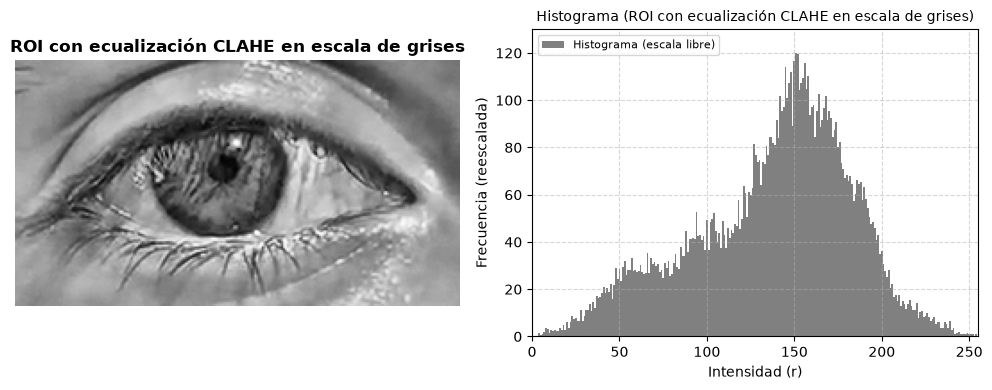

In [15]:
# Aplicar ecualización CLAHE
img_grises_clahe = cf.aplicar_clahe(roi_grises, clahe_clip, clahe_grilla)

# Visualización ROI + HISTOGRAMA
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
img = img_grises_clahe
titulo = "ROI con ecualización CLAHE en escala de grises"

# Imagen ecualizada
axes[0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(titulo, fontsize=12, fontweight="bold")
axes[0].axis("off")  

# Histograma 
hist_og = cf.histograma(img) if hasattr(cf, 'histograma') else np.bincount(img.ravel(), minlength=256)
hist_og = np.asarray(hist_og, dtype=float)

axes[1].bar(range(256), hist_og / hist_og.max() * 120, width=1, color="gray", edgecolor="none", label="Histograma (escala libre)")
axes[1].set_xlim(0, 255)
axes[1].set_ylim(0, 130)  
axes[1].set_xlabel("Intensidad (r)")
axes[1].set_ylabel("Frecuencia (reescalada)")
axes[1].set_title(f"Histograma ({titulo})", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 4. Estimación del centro y radio de la pupila

Algoritmos de contornos activos como **Snake** requieren la inicialización de una curva cercana al objeto que se desea segmentar. La función `estimar_pupila` resuelve la inicialización de forma automática, calculando el centro $(c_x, c_y)$ y el radio aproximado aprovechando que la pupila es la región más oscura y circular del frame.: 
1. Se marca el 5% de los píxeles más oscuros (se evitan dependencias de un umbral fijo).
2. Se aplica una *apertura morfológica* (elimina puntos aislados, ruido) y luego un *cierre* (rellena  huecos como el reflejo del flash).
3. Se mide la circularidad $C = \frac{4\pi \cdot \text{Área}}{\text{Perímetro}^2}$ de cada región conexa.
4. Se selecciona la región con el mayor valor de $\text{Circularidad} \times \sqrt{\text{Área}}$.

 
Limitación: el radio calculado resulta algo menor que el real debido a que  el percentil captura solo el núcleo más oscuro de la pupila. Para inicializar, se debe usar este radio escalado por algún factor.

ESTO HAY QUE CAMBIARLO PORQUE AHORA HACE ALGO DISTINTO, ES MÁS FINO. Y YA NO TIENE LA LIMITACION

Centro: (118.0, 60.0), Radio: 11.0 px


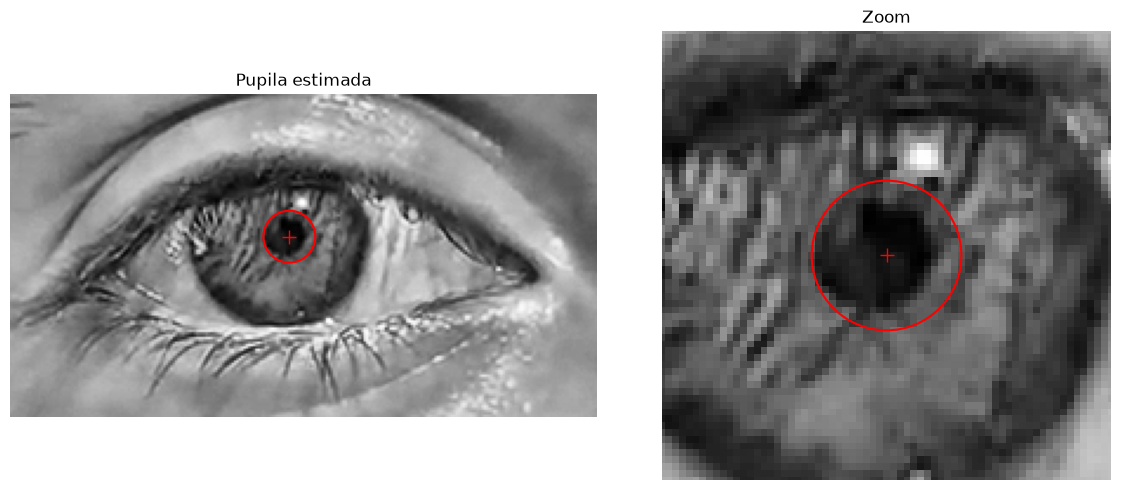

In [16]:
#===========================================================================
# Estimación de las coordenadas del centro y el radio de la pupila para SNAKE y WATERSHED.
#===========================================================================

# Llamada a la función de estimación.
resultado = seg.estimar_pupila(img_grises_clahe) 

if resultado is None:
    print("No se encontró ninguna región candidata.")
else:
    # Extrae coordenadas de centro y radio en píxeles.
    cx, cy, r = resultado 
    print(f"Centro: ({cx:.1f}, {cy:.1f}), Radio: {r:.1f} px")

    # Visualización de la estimación
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # Imagen completa con la pupila estimada.
    ax[0].imshow(img_grises_clahe, cmap="gray")
    ax[0].add_patch(plt.Circle((cx, cy), r, fill=False, color="r", linewidth=1.5))
    ax[0].plot(cx, cy, "r+", markersize=10)
    ax[0].set_title("Pupila estimada")

    # Zoom alrededor de la pupila, para ver si calza.
    margen = int(3 * r)
    ax[1].imshow(img_grises_clahe, cmap="gray")
    ax[1].add_patch(plt.Circle((cx, cy), r, fill=False, color="r", linewidth=1.5))
    ax[1].plot(cx, cy, "r+", markersize=10)
    ax[1].set_xlim(cx - margen, cx + margen)
    ax[1].set_ylim(cy + margen, cy - margen)   # eje y invertido: las filas crecen hacia abajo
    ax[1].set_title("Zoom")

    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()


## 5. Segmentación por umbralización automática (Otsu)

El método de **Otsu** calcula un umbral óptimo $T$ que maximiza la varianza entre clases (separando fondo y objeto). 

Puesto que la pupila es la estructura más oscura de la ROI, aplicamos el umbral sobre la imagen ecualizada `img_grises_clahe`. 

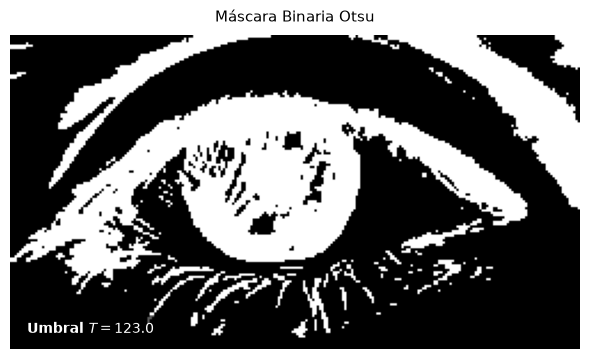

In [17]:
#===========================================================================
# Segmentación con OTSU
#===========================================================================
# Devuelve la máscara binaria y el valor del umbral T calculado.
umbral_otsu, mascara_otsu = seg.segmentar_otsu(img_grises_clahe)

# Gráfico

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(mascara_otsu, cmap="gray")
ax.set_title("Máscara Binaria Otsu", fontsize=11, pad=10)

texto_umbral = f"Umbral $T = {umbral_otsu}$"
ax.text(
    0.03, 0.05, texto_umbral,                   
    transform=ax.transAxes,
    fontsize=10,
    fontweight="bold",
    color="white",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="black", alpha=0.65, edgecolor="none") # Cuadro semi-transparente
)

ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Segmentación por contornos activos Snake

Los **contornos activos (Snake)** son curvas parametrizadas que evolucionan sobre la imagen minimizando una función de energía interna (suavidad y continuidad de la curva) y externa (gradientes de intensidad de la imagen).

### Estrategia de Inicialización:
1. Tomamos las coordenadas $(c_x, c_y)$ y el radio $r$ estimados previamente con `estimar_pupila`.
2. Multiplicamos el radio inicial por un factor (ej. $1.15 \times r$) para garantizar que la curva inicial rodee completamente la pupila y colapse hacia sus bordes reales.
3. Parámetros del planteo energético:
   * $\alpha$ (*alpha*): controla la elasticidad/tensión (cómo se mueve un punto de la curva individualmente).
   * $\beta$ (*beta*): controla la rigidez (evita esquinas pronunciadas, buscando formas circulares; cómo se mueven los puntos de la curva entre ellos).
   * $\gamma$ (*gamma*): paso de adaptación/velocidad de convergencia.

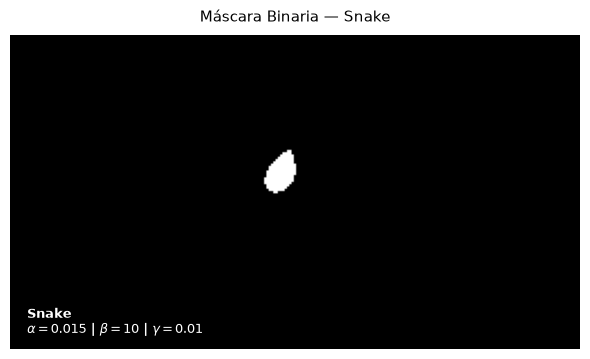

In [18]:
#===========================================================================
# Segmentación con SNAKE
#===========================================================================
cx, cy, r = seg.estimar_pupila(img_grises_clahe)


# Llamado a la función correspondiente.
# Nótese que 'factor_radio_inicial;, 'k', 'sigma', 'alpha','beta' y 'gamma' fueron
# definidos previamente, pues son parámetros guardados en ´config.yaml´

mascara_snake, contorno = seg.segmentar_snake(
    img_grises_clahe, cx, cy, r,
    factor_radio_inicial, k, sigma,alpha, beta, gamma)


# Visualización
fig, ax = plt.subplots(figsize=(6, 5))

ax.imshow(mascara_snake, cmap="gray")
ax.set_title("Máscara Binaria — Snake", fontsize=11, pad=10)

texto_snake = f"Snake\n$\\alpha={alpha}$ | $\\beta={beta}$ | $\\gamma={gamma}$"
ax.text(
    0.03, 0.05, texto_snake,
    transform=ax.transAxes,
    fontsize=9,
    fontweight="bold",
    color="white",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="black", alpha=0.65, edgecolor="none")
)

ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Segmentación por Watershed

Este método interpreta a una imagen en escala de grises como un mapa topográfico en 3D, donde la base (x,y) son las coordenadas espaciales de los píxeles, y la altura z es el nivel de gris. De esta forma, se define:
 * Los píxeles de baja intensidad actúan como valles, cuencas.
 * Los píxeles claros actúan como crestas de montañas.

El algoritmo simula la inundación de cada cuenca (mínimos locales de intensidad) hasta que el agua de dos cuencas distintas se encuentran. En ese punto, se levanta un *dique* en la línea divisoria de agua. 

Al finalizar el llenado, los diques construidos constituyen fronteras, dividiendo la imagen en regiones independientes.

El problema de este método reside en la sensibilidad al ruido y consecuente sobresegmentación. Para evitar esto, se aplica Watershed controlado por marcadores: el usuario o un algoritmo previo define explícitamente semillas internas y externas.
1. **Marcador interno (pupila):** un círculo/región reducida dentro del centro estimado $(c_x, c_y)$.
2. **Marcador externo (fondo):** la región lejana al centro de la pupila.

Estos marcadores se calculan por medio de la función `crear_marcadores`.

El algoritmo de Watershed se aplicó no sobre la imagen en escala de grises en este caso, sino sobre un *mapa de la magnitud del gradiente* generado por un 
**filtro Sobel**.
Así, las regiones homogéneas interiores se convierten en valles y los bordes de los objetos se transforman en crestas de montaña, obteniéndose una estructura topográfica ideal para trazar las líneas divisorias.



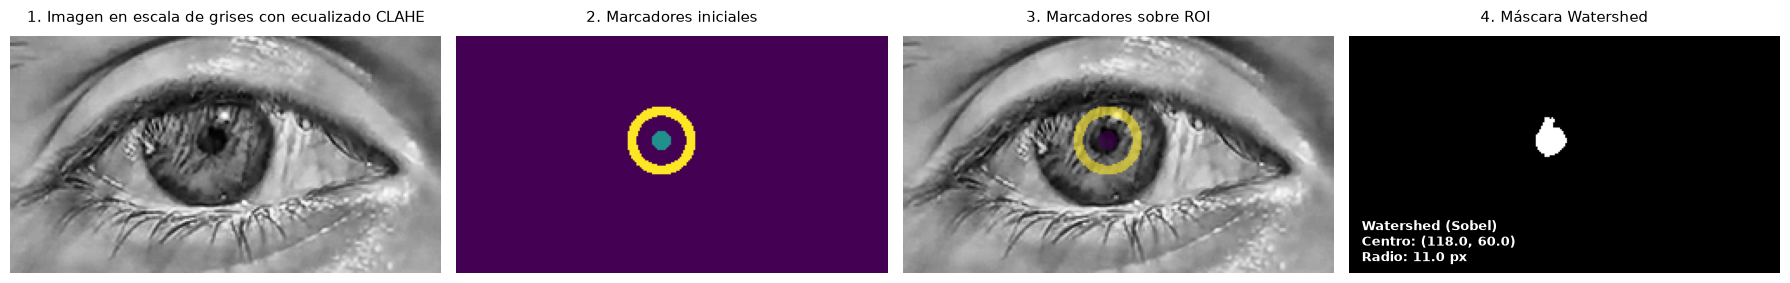

In [19]:
# ===========================================================================
# Segmentación con Watershed por Marcadores
# ===========================================================================

# Estimación e inicialización de marcadores
estimacion = seg.estimar_pupila(img_grises_clahe)

if estimacion is None:
    print("No se pudo estimar la pupila en esta imagen.")
else:
    cx, cy, r = estimacion

    # Crear marcadores y segmentar sobre el gradiente Sobel
    # Los parámetros factor_interior, factor_anillo_interior y factor_anillo_exterior están definidos en ´config.yaml´.
    marcadores = seg.crear_marcadores(img_grises_clahe, cx, cy, r,factor_interior, factor_anillo_interior, factor_anillo_exterior)
    mascara_watershed, etiquetas_watershed = seg.segmentar_watershed(img_grises_clahe, marcadores)

    # Visualización 
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

    # Entrada (ROI CLAHE)
    axes[0].imshow(img_grises_clahe, cmap="gray")
    axes[0].set_title("1. Imagen en escala de grises con ecualizado CLAHE", fontsize=11, pad=10)

    # Marcadores
    axes[1].imshow(marcadores, cmap="viridis", vmin=0, vmax=2)
    axes[1].set_title("2. Marcadores iniciales", fontsize=11, pad=10)

    # Marcadores superpuestos sobre la ROI
    axes[2].imshow(img_grises_clahe, cmap="gray")
    axes[2].imshow(
        np.ma.masked_where(marcadores == 0, marcadores),
        cmap="viridis",
        vmin=1,
        vmax=2,
        alpha=0.6
    )
    axes[2].set_title("3. Marcadores sobre ROI", fontsize=11, pad=10)

    # Máscara binaria
    axes[3].imshow(mascara_watershed, cmap="gray")
    axes[3].set_title("4. Máscara Watershed", fontsize=11, pad=10)
    texto_ws = f"Watershed (Sobel)\nCentro: ({cx:.1f}, {cy:.1f})\nRadio: {r:.1f} px"
    axes[3].text(
        0.03, 0.05, texto_ws,
        transform=axes[3].transAxes,
        fontsize=9,
        fontweight="bold",
        color="white",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="black", alpha=0.65, edgecolor="none")
    )

   
    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

## 8. Agrupar por K - Means (ROI a color)

Se aplicó K-means sobre las características saturación (S) e intensidad (V) del espacio HSV, con K entre 2 y 5. Una primera prueba sobre la ROI completa no permitió aislar la pupila: al ocupar menos del 1 % de los píxeles, el algoritmo, que reparte los grupos según dónde se concentran los datos, los destina a las zonas abundantes (piel, pestañas, iris) y la pupila queda mezclada con alguna de ellas. Por este motivo el método se aplicó sobre una ventana local de tamaño proporcional al radio (3·r) alrededor de la pupila estimada con `estimar_pupila`, donde la pupila deja de ser una fracción despreciable de los datos. Dentro de esa ventana, el grupo correspondiente a la pupila se eligió como el que predomina en el círculo central de radio r.

Los resultados dependen claramente de K. Con K=2 y K=3 hay pocos grupos para separar tantas zonas, por lo que el grupo más oscuro absorbe también sombras y regiones marrones del iris, y el contorno se extiende más allá de la pupila. Con K=4 y K=5 el contorno se ajusta mejor al núcleo oscuro, porque hay grupos suficientes para separar la pupila del iris. La diferencia entre ambas áreas es pequeña, lo que sugiere que a partir de K=4 el resultado se estabiliza.

Aun con K=4 y K=5, la máscara tiene dos limitaciones. Por un lado, captura la parte más oscura de la pupila pero deja afuera una zona azulada de su borde, que en el espacio S–V queda más cerca de otro grupo que del negro puro; por eso el área tiende a subestimar la pupila real. Por otro, al clasificar píxeles por color sin considerar su posición, aparecen regiones pequeñas aisladas (pestañas, sombras, reflejo corneal) que comparten el grupo de la pupila.

En conjunto, K-means resulta sensible a la elección de K y no incorpora información espacial, y además depende de una estimación previa de la posición de la pupila para funcionar. Estas características lo hacen menos robusto que Watershed para aplicarlo a todos los cuadros del video, aunque sirve como comparación de un enfoque basado en color. 

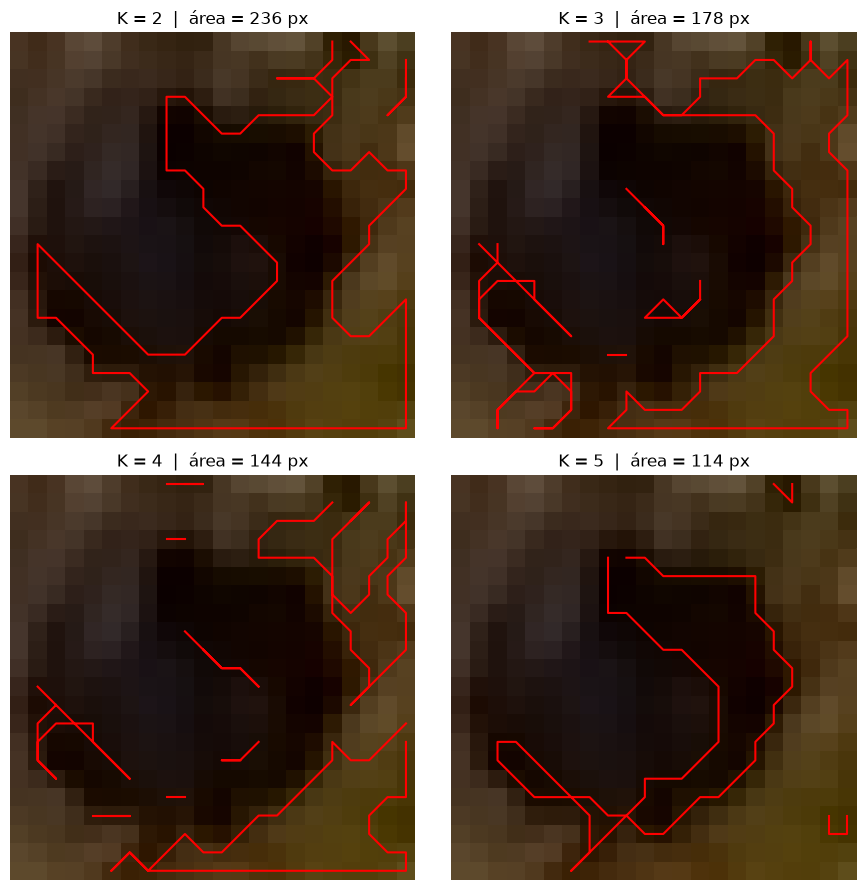

In [20]:
cx, cy, r = seg.estimar_pupila(img_grises_clahe)

def mostrar_kmeans(roi, cx, cy, r, ks=(2, 3, 4, 5), factor_ventana=factor_ventana, zoom=True):
    """
    Corre segmentar_kmeans para cada K y grafica el contorno de la máscara
    sobre la ROI a color. Devuelve un dict {K: máscara}.
    """

    mascaras = {}
    for k in ks:
        mascaras[k] = seg.segmentar_kmeans(roi, cx, cy, r, k=k, factor_ventana=factor_ventana)

    # recorte para ver la pupila más de cerca (solo para graficar)
    alto, ancho = roi.shape[:2]
    mitad = int(factor_ventana * r)
    if zoom:
        x0, x1 = max(int(cx) - mitad, 0), min(int(cx) + mitad, ancho)
        y0, y1 = max(int(cy) - mitad, 0), min(int(cy) + mitad, alto)
    else:
        x0, x1, y0, y1 = 0, ancho, 0, alto

    n = len(ks)
    filas = (n + 1) // 2
    fig, ejes = plt.subplots(filas, 2, figsize=(9, 4.5 * filas))
    ejes = np.atleast_1d(ejes).ravel()

    for eje, (k, mascara) in zip(ejes, mascaras.items()):
        eje.imshow(roi[y0:y1, x0:x1])
        contornos, _ = cv2.findContours(mascara[y0:y1, x0:x1],
                                        cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        for c in contornos:
            eje.plot(c[:, 0, 0], c[:, 0, 1], "r", linewidth=1.5)
        area = int((mascara > 0).sum())
        eje.set_title(f"K = {k}  |  área = {area} px")
        eje.axis("off")

    for eje in ejes[n:]:      # apaga ejes sobrantes si K es impar
        eje.axis("off")

    plt.tight_layout()
    plt.show()
    return mascaras

mascaras_kmeans = mostrar_kmeans(roi, cx, cy, r, ks=(2, 3, 4, 5),factor_ventana=factor_ventana)
mascara_kmeans_4 = mascaras_kmeans[4]


## 8. Comparación de segmentaciones.
Resultados de la segmentación. Falta análisis.

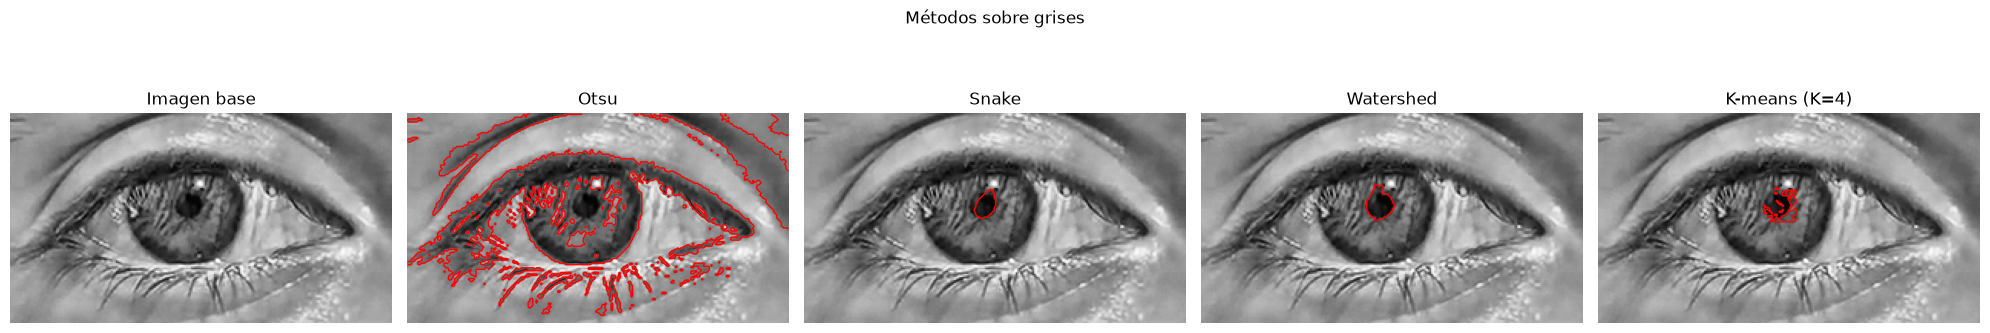

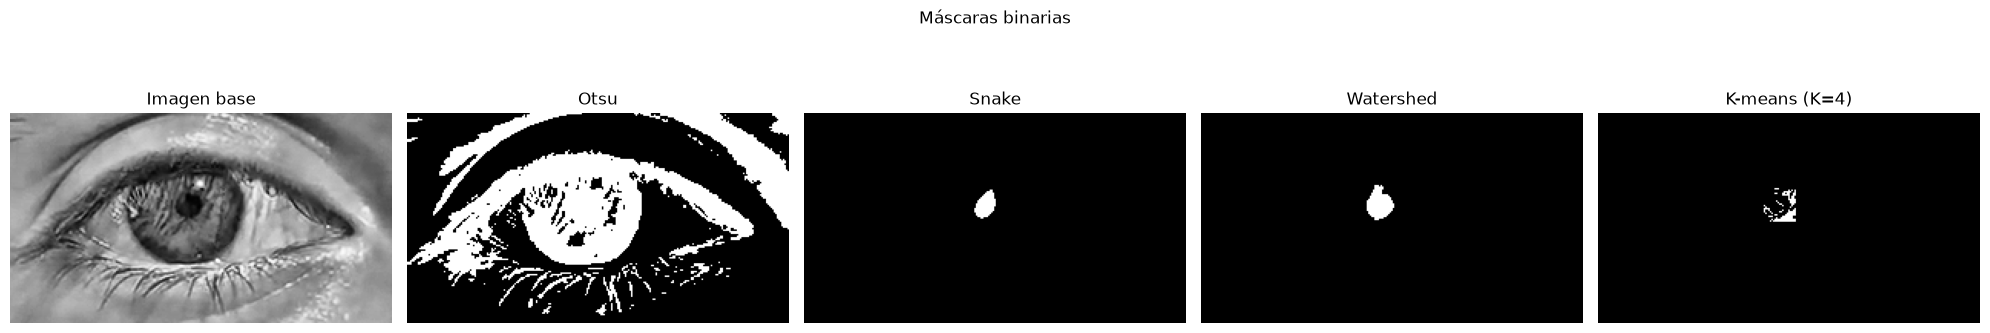

In [21]:

def mostrar_mascaras_sobre_grises(base, mascaras, titulo, cmap_base="gray"):
    """Muestra la imagen base y, al lado, cada máscara con su contorno
    superpuesto sobre la base, para poder verificar si calza con la pupila."""
    n = len(mascaras) + 1
    fig, ax = plt.subplots(1, n, figsize=(4 * n, 4))

    ax[0].imshow(base, cmap=cmap_base)
    ax[0].set_title("Imagen base")

    for i, (nombre, m) in enumerate(mascaras.items(), start=1):
        ax[i].imshow(base, cmap=cmap_base)
        ax[i].contour(m > 0, levels=[0.5], colors="r", linewidths=1)
        ax[i].set_title(nombre)

    for a in ax:
        a.axis("off")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def mostrar_mascaras_binarias(base, mascaras, titulo):
    """Muestra la imagen base y las máscaras binarias de cada método."""

    n = len(mascaras) + 1
    fig, ax = plt.subplots(1, n, figsize=(4 * n, 4))

    # Imagen base
    ax[0].imshow(base, cmap="gray")
    ax[0].set_title("Imagen base")

    # Máscaras binarias
    for i, (nombre, m) in enumerate(mascaras.items(), start=1):
        ax[i].imshow(m > 0, cmap="gray", vmin=0, vmax=1)
        ax[i].set_title(nombre)

    for a in ax:
        a.axis("off")

    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

mascaras = {
    "Otsu": mascara_otsu,
    "Snake": mascara_snake,
    "Watershed": mascara_watershed,
    "K-means (K=4)": mascara_kmeans_4,
}

mostrar_mascaras_sobre_grises(img_grises_clahe, mascaras, "Métodos sobre grises")
mostrar_mascaras_binarias(img_grises_clahe, mascaras, "Máscaras binarias")



## Selección de frames para la anotación manual
Se observan distintos frames del video para seleccionar varios y generar una máscara de referencia contra la cual comparar todas las máscaras generadas

True


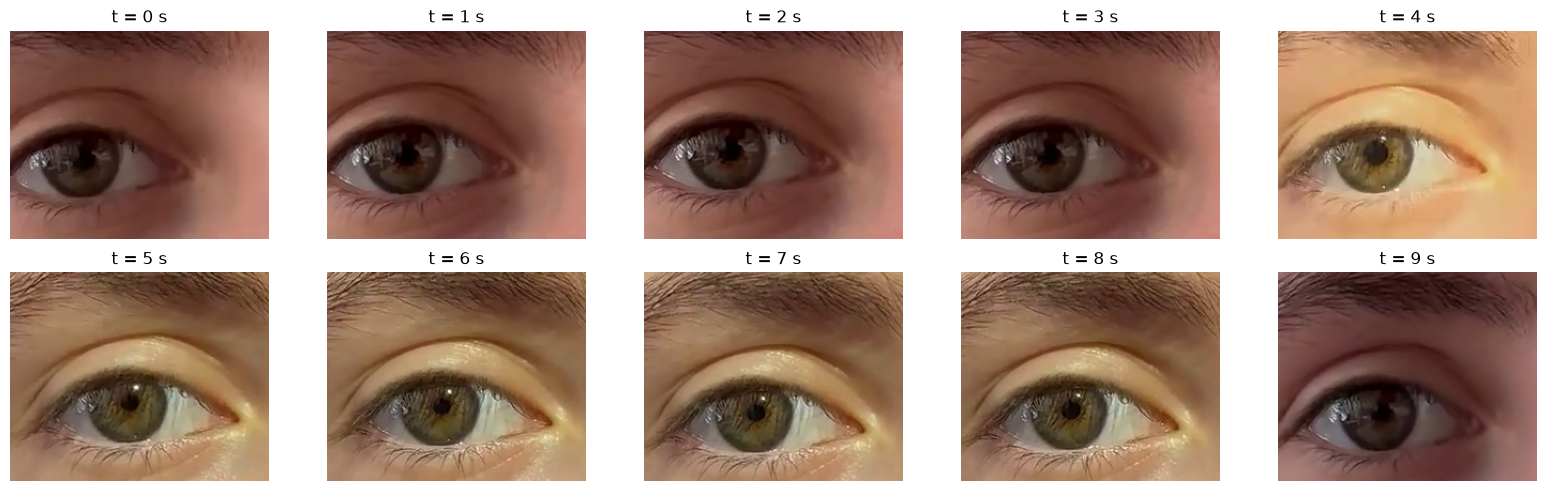

In [22]:
from src.modulo1.carga_muestreo import extraer_frame, recortar_roi

ruta_video = raiz / cfg["entrada"]["video_path"]
print(ruta_video.exists())      # tiene que dar True; si da False, el video no está en tu repo

tiempos = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]    

fig, ejes = plt.subplots(2, 5, figsize=(16, 5))
for eje, t in zip(ejes.ravel(), tiempos):
    frame = extraer_frame(ruta_video, t)
    eje.imshow(recortar_roi(frame, cfg["roi"]))
    eje.set_title(f"t = {t} s")
    eje.axis("off")
plt.tight_layout()
plt.show()

In [23]:
def procesar_frame(t, cfg, raiz):
    """Frame en t segundos -> ROI -> grises + CLAHE -> pupila -> 4 métodos.
    Devuelve un dict con todo; no grafica nada."""

    # 1. frame y ROI (funciones de tu compañero)
    frame = extraer_frame(raiz / cfg["entrada"]["video_path"], t)
    roi = recortar_roi(frame, cfg["roi"])

    # 2. grises + CLAHE: copiá lo que hiciste en tu notebook
    img_clahe = cf.aplicar_clahe(cf.conv_grises(roi),clahe_clip,clahe_grilla) 

    # 3. estimar la pupila (puede devolver None, por ejemplo en un parpadeo)
    pupila = seg.estimar_pupila(img_clahe)
    if pupila is None:
        return {"roi": roi, "gris": img_clahe, "pupila": None, "mascaras": {}}
    cx, cy, r = pupila

    # 4. los cuatro métodos
    mascaras = {}
    _, mascaras["Otsu"] = seg.segmentar_otsu(img_clahe)

    mascaras["Snake"], _ = seg.segmentar_snake(
        img_clahe, cx, cy, r,
        factor_radio_inicial, k, sigma, alpha, beta, gamma)

    marcadores = seg.crear_marcadores(img_clahe, cx, cy, r,factor_interior, factor_anillo_interior, factor_anillo_exterior)
    mascaras["Watershed"] , etiquetas= seg.segmentar_watershed(
        img_clahe, marcadores)   

    mascaras[f"K-means (K={k_clusters})"] = seg.segmentar_kmeans(
        roi, cx, cy, r, k=k_clusters, factor_ventana=factor_ventana)

    return {"roi": roi, "gris": img_clahe, "pupila": (cx, cy, r), "mascaras": mascaras}


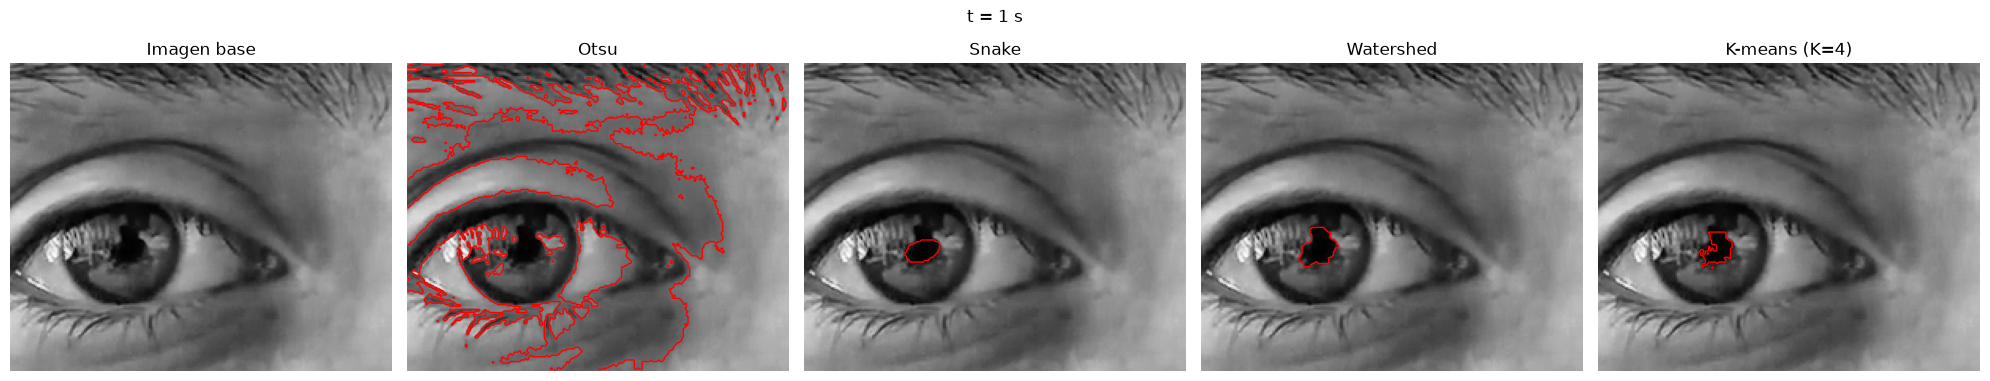

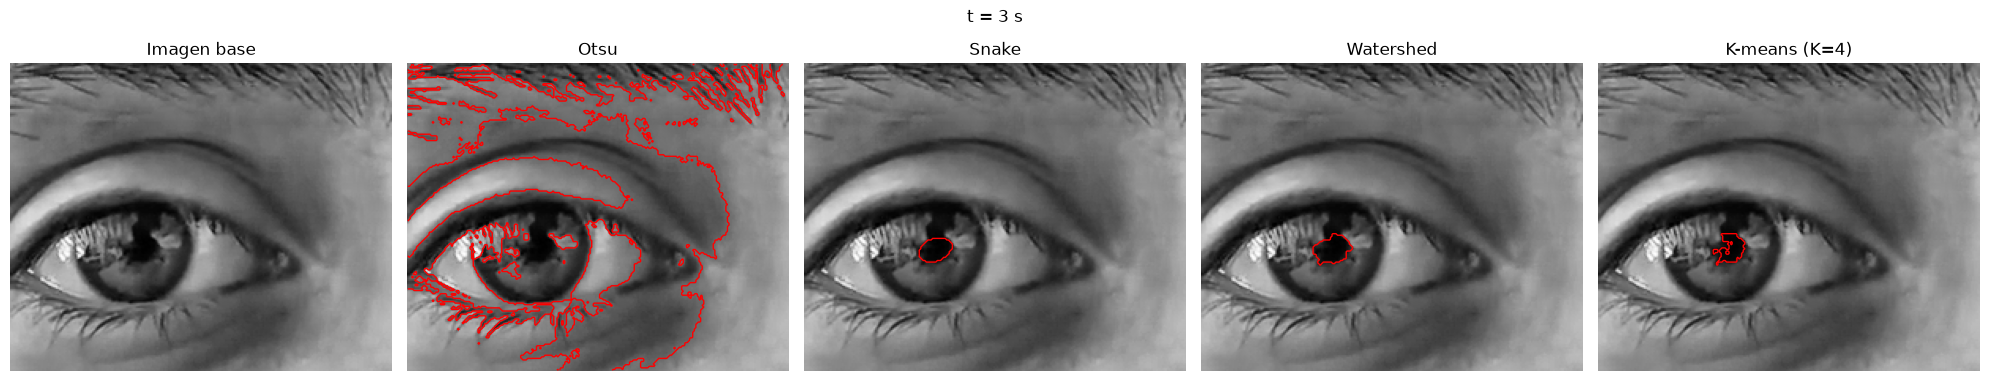

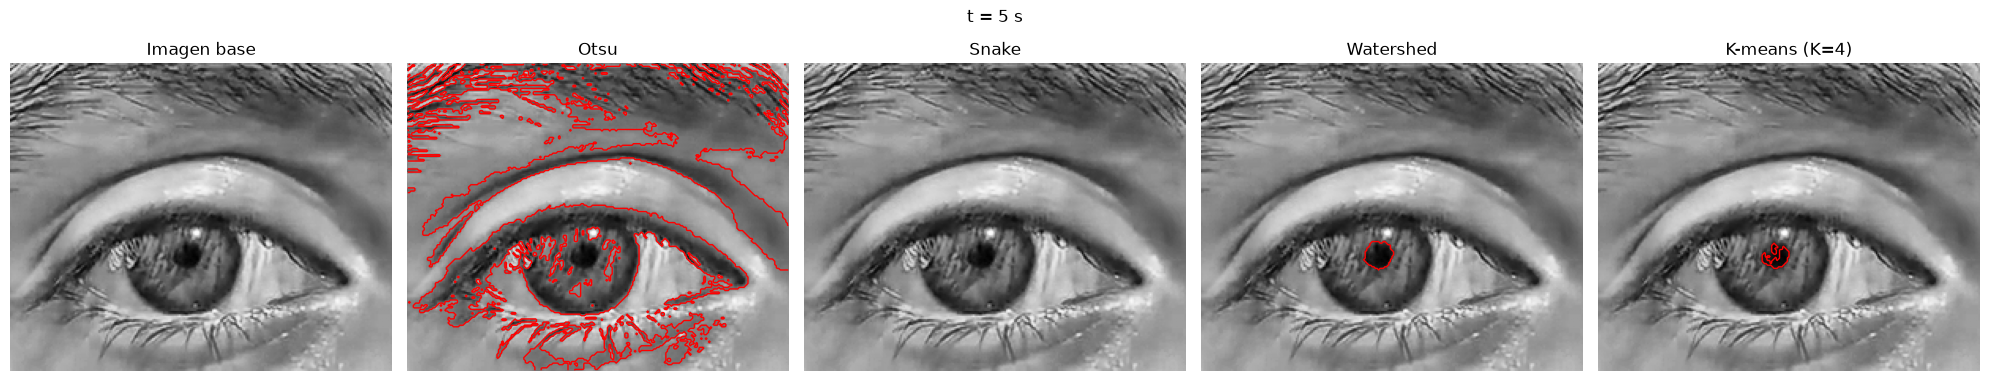

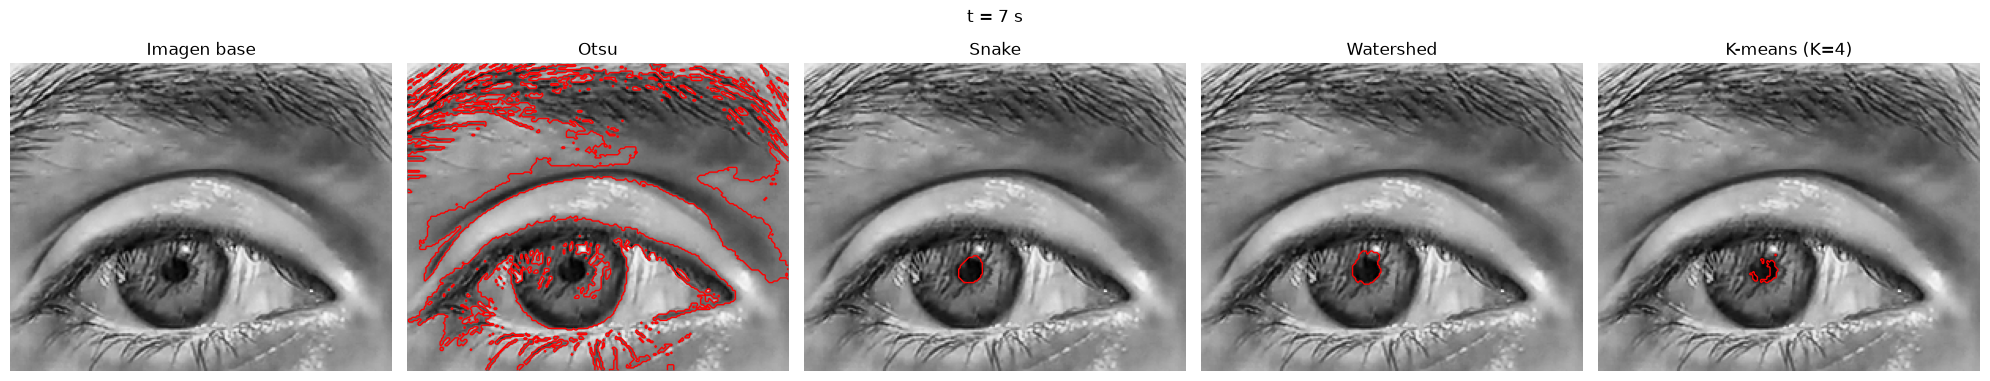

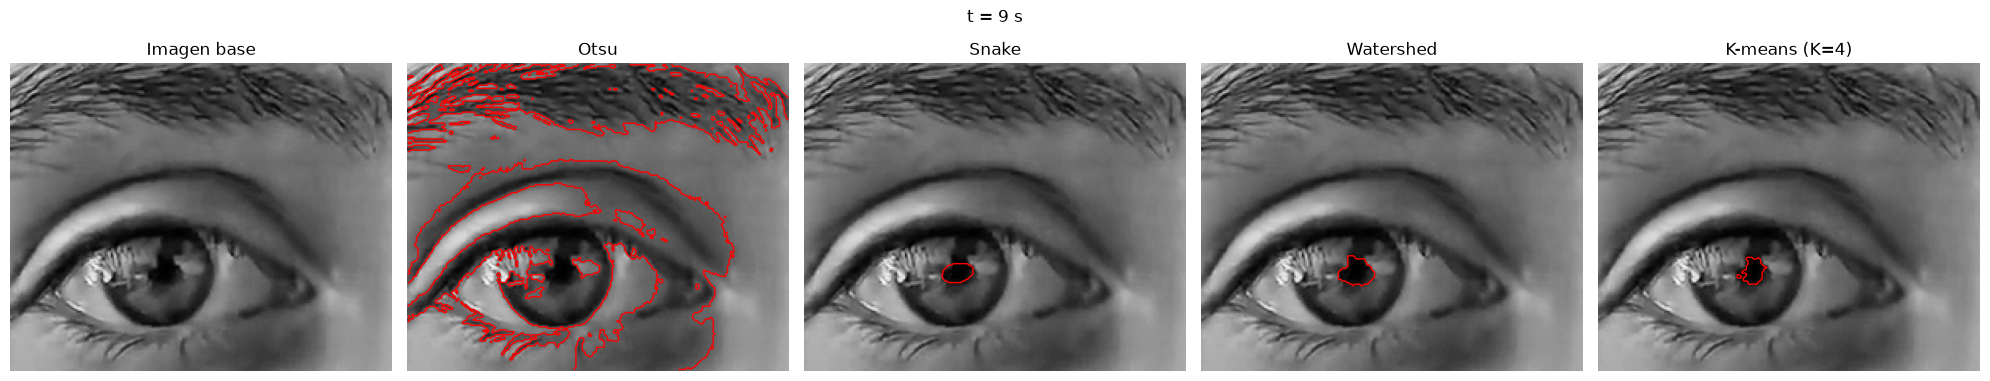

In [24]:
tiempos_anotar = [1, 3, 5, 7, 9]
resultados = {}

for t in tiempos_anotar:
    res = procesar_frame(t, cfg, raiz)
    resultados[t] = res
    if res["pupila"] is None:
        print(f"t = {t} s: no se encontró la pupila")
        continue
    mostrar_mascaras_sobre_grises(res["gris"], res["mascaras"], f"t = {t} s")